**Value at Risk Forecasting and Backtesting using Single Asset Case**

**Final Capstone Project**

**IIT Ropar**

**Group Members - Georgy S Pulayath, Joshi Bhavin Rasikbhai, Prabhujeet Sahu, Shrenik Nandre**

**Guide: Prof. Punit Pasricha (IIT Ropar)**

## How to read this notebook

This is the **single-asset normal VaR** in section 4 of the report. It is not a GARCH model. Volatility is the trailing standard deviation of log portfolio changes, and VaR is that volatility times the portfolio value times 1.645 (the 95% normal critical value).

The book is the same 1,000 Nifty units as the GARCH study (₹21,03,750 on 4 January 2005). The report's average **AE ratio is about 2.33**. An illustrated day in the report, with portfolio value ₹20,32,200 and daily volatility 1.09%, gives

```text
1-day 95% VaR = 0.0109 * 20,32,200 * 1.645 = ₹36,447.40
```

The rolling loop uses a 252-day window and a 21-day test. Expected violations inside one 21-day test are set to 1 (about 5% of 21). Kupiec, Christoffersen independence, and conditional coverage are applied to the stacked breach sequence. The report describes those p-values as near 1.


In [224]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)


E:\MSDSM\Sem-4\FCP\Single Asset Case


In [225]:
# pandas/numpy, plots, and chi-square p-values for the coverage tests.
# ARIMA, arch, and yfinance are imported from a shared setup and are not used
# in the single-asset calculation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model 
from tabulate import tabulate
from scipy.stats import chi2


In [226]:
# Dates and NIFTY Index from the shared workbook.

nifty_df = pd.read_excel(NIFTY_PATH)  # data/Nifty50_data.xlsx


In [227]:
# 1,000 units held fixed. Opening value is 1,000 * first Nifty level
# = ₹21,03,750 on 4 January 2005.

shares_held = 1000 # Number of shares purchased
initial_investment = shares_held * nifty_df['NIFTY Index'] # Initial investment amount
# Calculate the portfolio value based on the number of shares held
nifty_df['Portfolio Value'] = shares_held * nifty_df['NIFTY Index']


In [228]:
# Working frame: date, index, portfolio value.

nf_df = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']]
nf_df.head()


,Dates,NIFTY Index,Portfolio Value
0,2005-01-04,2103.75,2103750.0
1,2005-01-05,2032.20,2032200.0
2,2005-01-06,1998.35,1998350.0
3,2005-01-07,2015.50,2015500.0
4,2005-01-10,1982.00,1982000.0


In [229]:
# 252-day estimation window (about one trading year).
# z_score 1.645 is the 95% one-sided normal critical value.
# expected_violations = 1 means one breach is allowed per 21-day test
# (the report's 95% confidence).

# Define constants
window_size = 252  # Rolling window size
z_score = 1.645    # 95% confidence level
expected_violations = 1  # Expected violations per rolling window


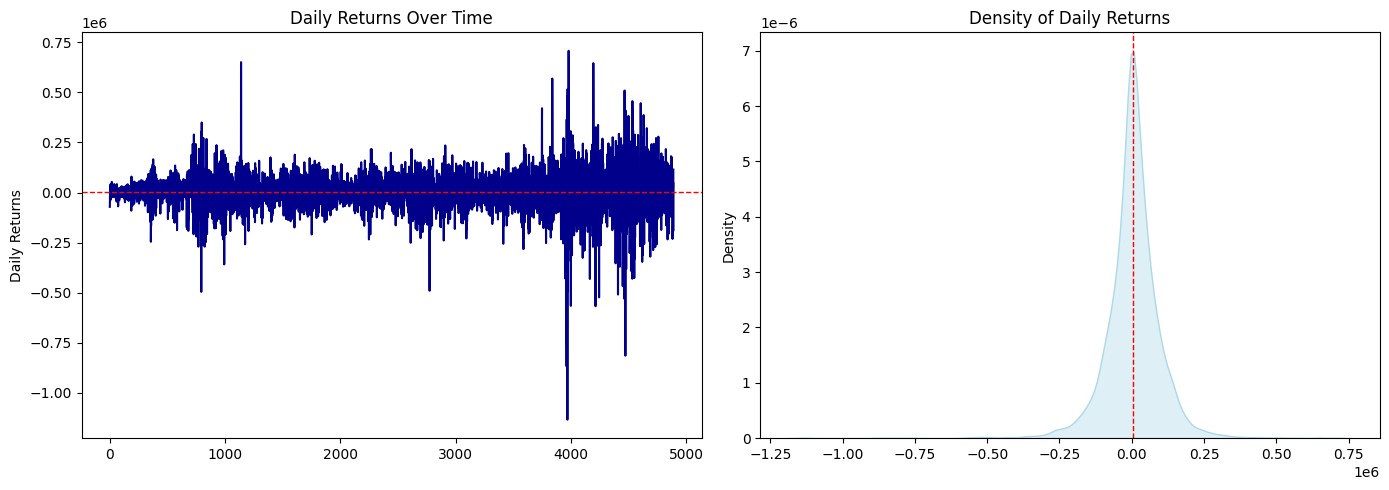

In [230]:
# Rupee profit-and-loss = simple return * previous portfolio value.
# Left panel: clustering. Right panel: the density the normal VaR is assuming.

def plot_returns(rets):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Line plot of daily returns
    sns.lineplot(x=range(len(rets)), y=rets, color='darkblue', ax=axes[0])
    axes[0].axhline(y=rets.mean(), color='red', linestyle='--', linewidth=1)
    axes[0].set_xlabel('')
    axes[0].set_ylabel('Daily Returns')
    axes[0].set_title('Daily Returns Over Time')
    
    # Density plot of daily returns
    sns.kdeplot(rets, fill=True, color='lightblue', alpha=0.4, ax=axes[1])
    axes[1].axvline(x=rets.mean(), color='red', linestyle='--', linewidth=1)
    axes[1].set_xlabel('')
    axes[1].set_title('Density of Daily Returns')
    
    plt.tight_layout()
    plt.show()
plot_returns((nf_df['Portfolio Value'].pct_change().dropna() * nf_df['Portfolio Value'].shift(1).dropna()))


In [231]:
# For every start date: estimate daily log-volatility on the last 21 days
# of a 252-day window, convert to a rupee VaR with z = 1.645, then count
# how many of the next 21 portfolio changes are worse than -VaR.
# AE for that window = breaches / 1.
# Kupiec's test at the bottom of the cell compares the pooled breach rate with 5%.

var_list = []
actual_violations_list = []
ae_ratio_list = []
forecast_dates = []  # Store the forecast dates for visualization
loss_list = []  # Store the actual losses for visualization
violation_sequence = []  # Store 1 for violation, 0 for no violation

import numpy as np
import pandas as pd
from scipy.stats import chi2

var_list = []
actual_violations_list = []
ae_ratio_list = []
forecast_dates = []  # Store the forecast dates for visualization
loss_list = []  # Store the actual losses for visualization
violation_sequence = []  # Store 1 for violation, 0 for no violation

# Iterate through the dataframe with a rolling window
for start in range(len(nf_df) - window_size - 21): 
    end = start + window_size
    test_start = end
    test_end = test_start + 21
    
    window_data = nf_df.iloc[start:end]
    test_data = nf_df.iloc[test_start:test_end]
    rolling_volatility = window_data['Portfolio Value'].apply(np.log).diff().rolling(window=21).std().iloc[-1]
    #print(window_data.head())
    daily_volatility = rolling_volatility
    portfolio_value = window_data['Portfolio Value'].iloc[-1]
    potential_loss = daily_volatility * portfolio_value
    var_1d = z_score * potential_loss
    
    # Backtest: Count violations
    actual_losses = test_data['Portfolio Value']-test_data['Portfolio Value'].shift(1)
    actual_losses=actual_losses.dropna()

    #print(actual_losses)
    #print(var_1d)
    violations = (actual_losses < -var_1d).sum()
    violation_sequence.extend((actual_losses < -var_1d).astype(int).tolist())
    
    # Compute AE ratio
    ae_ratio = violations / expected_violations
    
    # Store results
    var_list.append(var_1d)
    actual_violations_list.append(violations)
    ae_ratio_list.append(ae_ratio)
    loss_list.extend(actual_losses.tolist())
    start_date = nf_df['Dates'].iloc[test_start]
    end_date = nf_df['Dates'].iloc[test_end]
    forecast_dates.append(f"{start_date} : {end_date}")

# Kupiec's Unconditional Coverage Test
def kupiec_test(violations, total_obs, alpha=0.05):
    if total_obs == 0:  # No observations, return neutral test statistic
        return 0, 1.0
    
    p_hat = violations / total_obs if total_obs > 0 else 0  # Observed violation probability
    
    if p_hat > 0:
        likelihood_h0 = (1 - alpha) ** (total_obs - violations) * alpha ** violations
        likelihood_h1 = (1 - p_hat) ** (total_obs - violations) * (p_hat ** violations if violations > 0 else 1)
        
        if likelihood_h1 == 0:  # Avoid division by zero
            return 0, 1.0
        
        test_stat = -2 * np.log(likelihood_h0 / likelihood_h1)
        p_value = 1 - chi2.cdf(test_stat, df=1)
    else:
        test_stat, p_value = 0, 1.0  # Neutral values if no violations
    
    return test_stat, p_value


In [232]:
# Christoffersen independence: a breach should not change the probability
# of a breach on the next day. The test counts the four transitions
# (calm-calm, calm-breach, breach-calm, breach-breach).

# Christoffersen's Independence Test
def christoffersen_test(violation_sequence):
    n00, n01, n10, n11 = 0, 0, 0, 0
    for i in range(1, len(violation_sequence)):
        if violation_sequence[i-1] == 0 and violation_sequence[i] == 0:
            n00 += 1
        elif violation_sequence[i-1] == 0 and violation_sequence[i] == 1:
            n01 += 1
        elif violation_sequence[i-1] == 1 and violation_sequence[i] == 0:
            n10 += 1
        elif violation_sequence[i-1] == 1 and violation_sequence[i] == 1:
            n11 += 1
    
    p01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    p11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    
    if p01 > 0 and p11 > 0:
        likelihood_h0 = ((1 - p01) ** n00) * (p01 ** n01) * ((1 - p11) ** n10) * (p11 ** n11)
        p_hat = (n01 + n11) / (n00 + n01 + n10 + n11)
        
        if p_hat > 0:
            likelihood_h1 = ((1 - p_hat) ** (n00 + n10)) * (p_hat ** (n01 + n11))
            if likelihood_h1 > 0:
                test_stat = -2 * np.log(likelihood_h0 / likelihood_h1)
                p_value = 1 - chi2.cdf(test_stat, df=1)
            else:
                test_stat, p_value = 0, 1.0
        else:
            test_stat, p_value = 0, 1.0
    else:
        test_stat, p_value = 0, 1.0
    
    return test_stat, p_value


In [233]:
# Conditional coverage = Kupiec statistic + independence statistic.
# Compared with a chi-square distribution on 2 degrees of freedom.

# Joint Conditional Coverage Test
def conditional_coverage_test(violations, total_obs, violation_sequence):
    uc_stat, uc_p = kupiec_test(violations, total_obs)
    ind_stat, ind_p = christoffersen_test(violation_sequence)
    joint_stat = uc_stat + ind_stat
    joint_p_value = 1 - chi2.cdf(joint_stat, df=2)
    return joint_stat, joint_p_value


In [234]:
# The report describes these p-values as near 1, i.e. the tests do not
# reject correct coverage or independence, while the average AE ratio
# across windows is about 2.33.

# Perform tests
total_observations = len(violation_sequence)
total_violations = sum(violation_sequence)

kupiec_stat, kupiec_p = kupiec_test(total_violations, total_observations)
ind_stat, ind_p = christoffersen_test(violation_sequence)
joint_stat, joint_p = conditional_coverage_test(total_violations, total_observations, violation_sequence)

print(f"Kupiec Unconditional Coverage Test: Chi-Square Statistic = {kupiec_stat:.4f}, p-value = {kupiec_p:.4f}")
print(f"Christoffersen Independence Test: Chi-Square Statistic = {ind_stat:.4f}, p-value = {ind_p:.4f}")
print(f"Conditional Coverage Test: Chi-Square Statistic = {joint_stat:.4f}, p-value = {joint_p:.4f}")


Kupiec Unconditional Coverage Test: Chi-Square Statistic = 0.0000, p-value = 1.0000
Christoffersen Independence Test: Chi-Square Statistic = 0.0000, p-value = 1.0000
Conditional Coverage Test: Chi-Square Statistic = 0.0000, p-value = 1.0000


In [235]:
# One row per 21-day test: the VaR that was in force, the breach count, the AE ratio.

results_df = pd.DataFrame({
    'Forecast Date': forecast_dates,
    'VaR 1-day': var_list,
    'Actual Violations': actual_violations_list,
    'AE Ratio': ae_ratio_list
})
results_df.head(10)


,Forecast Date,VaR 1-day,Actual Violations,AE Ratio
0,2005-12-22 00:00:00 : 2006-01-20 00:00:00,49118.428745,1,1.0
1,2005-12-23 00:00:00 : 2006-01-23 00:00:00,48305.467276,1,1.0
2,2005-12-26 00:00:00 : 2006-01-24 00:00:00,49532.646874,0,0.0
3,2005-12-27 00:00:00 : 2006-01-25 00:00:00,52718.645346,0,0.0
4,2005-12-28 00:00:00 : 2006-01-26 00:00:00,54663.009758,0,0.0
5,2005-12-29 00:00:00 : 2006-01-27 00:00:00,54330.495043,0,0.0
6,2005-12-30 00:00:00 : 2006-01-30 00:00:00,51606.129556,0,0.0
7,2006-01-02 00:00:00 : 2006-01-31 00:00:00,49592.003195,0,0.0
8,2006-01-03 00:00:00 : 2006-02-01 00:00:00,49572.218361,0,0.0
9,2006-01-04 00:00:00 : 2006-02-02 00:00:00,49155.141689,0,0.0


In [236]:
# Windows whose AE ratio landed near 1 (between 0.8 and 1.2).
# These are the well-calibrated slices, not the average. The average in the
# report is about 2.33.

filtered_results = results_df[(results_df['AE Ratio'] >= 0.8) & (results_df['AE Ratio'] <= 1.2)]
print("following are VaR values with AE ratio close to 1")
print(tabulate(filtered_results, headers='keys', tablefmt='pretty'))


following are VaR values with AE ratio close to 1
+------+-------------------------------------------+--------------------+-------------------+----------+
|      |               Forecast Date               |     VaR 1-day      | Actual Violations | AE Ratio |
+------+-------------------------------------------+--------------------+-------------------+----------+
|  0   | 2005-12-22 00:00:00 : 2006-01-20 00:00:00 | 49118.42874454266  |         1         |   1.0    |
|  1   | 2005-12-23 00:00:00 : 2006-01-23 00:00:00 | 48305.467276450916 |         1         |   1.0    |
|  34  | 2006-02-08 00:00:00 : 2006-03-09 00:00:00 | 49507.81125302573  |         1         |   1.0    |
|  35  | 2006-02-09 00:00:00 : 2006-03-10 00:00:00 | 46633.62175916169  |         1         |   1.0    |
|  36  | 2006-02-10 00:00:00 : 2006-03-13 00:00:00 | 46633.62175916169  |         1         |   1.0    |
|  37  | 2006-02-13 00:00:00 : 2006-03-14 00:00:00 | 45869.93459775849  |         1         |   1.0    |
|  38

In [237]:
# Share of windows that fell inside that 0.8-1.2 AE band.
# The name in the print statement says Proportion of Failures; the ratio is
# the share of windows inside the band.

#Proportion of Failures (POf) test
pof = len(filtered_results) / len(results_df)
print(f"Proportion of Failures (POf): {pof:.2%}")   


Proportion of Failures (POf): 29.42%


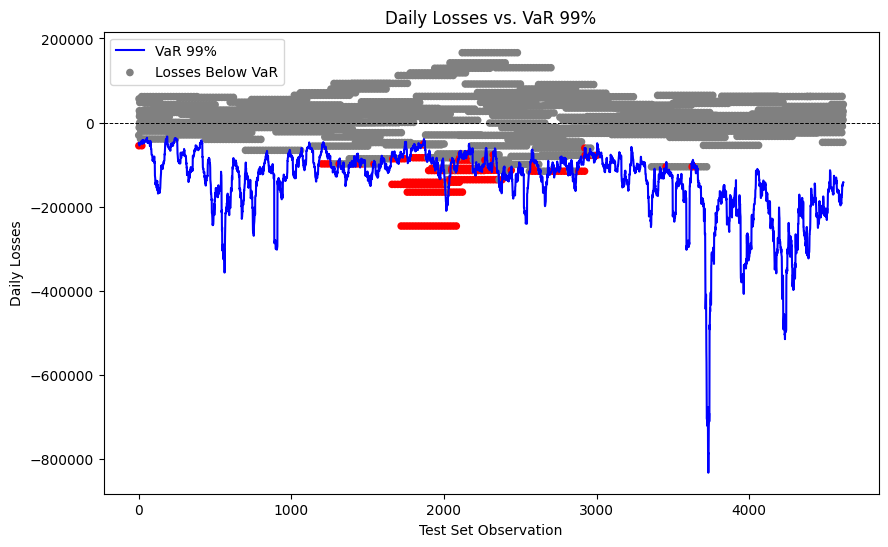

In [238]:
# Daily portfolio changes against the VaR path.
# VaR is stored as a positive loss amount and plotted with a minus so it
# sits on the same side as negative profit-and-loss.
# The title says 99%; z_score in this notebook is 1.645, which is 95%.

min_length = min(len(var_list), len(loss_list))
var_plot = var_list[:min_length]
var_plot = [-x for x in var_plot] 
loss_plot = loss_list[:min_length]

# Plot Daily Losses vs. VaR
plt.figure(figsize=(10, 6))
plt.plot(range(1, min_length + 1), var_plot, label='VaR 99%', color='blue')
plt.scatter(range(1, min_length + 1), loss_plot, 
            c=['red' if x < var_plot[i] else 'gray' for i, x in enumerate(loss_plot)], 
            s=20, label='Daily Losses')
plt.axhline(y=0, color='black', linestyle='--', linewidth=0.7)
plt.ylabel('Daily Losses')
plt.xlabel('Test Set Observation')
plt.title('Daily Losses vs. VaR 99%')
plt.legend(['VaR 99%', 'Losses Below VaR'], loc='upper left')
plt.show()
